# Experiment 12: Image Inpainting using GANs

**Aim:** Fill in missing regions of images with a **context-encoder GAN**: a generator that reconstructs a masked region from its
surroundings, trained with a reconstruction (L1) loss plus an adversarial loss from a discriminator.

In [1]:
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageDraw
keras.utils.set_random_seed(12)
rng = np.random.default_rng(12)
BATCH, N_TRAIN, EPOCHS = 64, 30000, 8
print("TensorFlow", tf.__version__, "| train images", N_TRAIN, "| epochs", EPOCHS)

I0000 00:00:1792695317.947242   10501 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792695319.714215   10501 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | train images 30000 | epochs 8


## 1. Data and masks
Fashion-MNIST images are padded to 32x32 and scaled to [-1, 1]. Training masks are a mix of random rectangles and irregular brush
strokes, so that the model learns general-purpose inpainting.

train (30000, 32, 32, 1) | test (2000, 32, 32, 1) | range [-1.0, 1.0]


mask pool: (5000, 32, 32, 1) | mean masked fraction: 17.5%


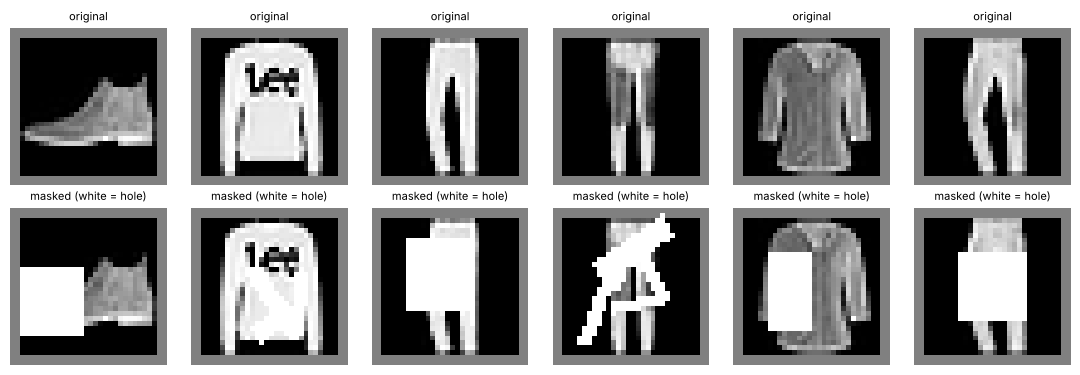

In [2]:
(x_all, _), (x_te, _) = keras.datasets.fashion_mnist.load_data()
prep = lambda a: np.pad(a.astype("float32") / 127.5 - 1, ((0, 0), (2, 2), (2, 2)))[..., None]
x_train, x_test = prep(x_all[:N_TRAIN]), prep(x_te[:2000])
print("train", x_train.shape, "| test", x_test.shape, "| range [%.1f, %.1f]" % (x_train.min(), x_train.max()))
def make_mask(kind=None):
    kind = kind or rng.choice(["rect", "strokes"])
    m = Image.new("L", (32, 32), 0); d = ImageDraw.Draw(m)
    if kind == "rect":
        h, w = rng.integers(8, 17, 2); y, x = rng.integers(2, 32 - h - 1), rng.integers(2, 32 - w - 1)
        d.rectangle([x, y, x + w, y + h], fill=1)
    elif kind == "center":
        d.rectangle([9, 9, 22, 22], fill=1)
    else:
        for _ in range(rng.integers(2, 5)):
            pts = [tuple(rng.integers(3, 29, 2)) for _ in range(rng.integers(2, 4))]
            d.line(pts, fill=1, width=int(rng.integers(3, 6)))
    return np.array(m, "float32")[..., None]
mask_pool = np.stack([make_mask() for _ in range(5000)])
print("mask pool:", mask_pool.shape, "| mean masked fraction: %.1f%%" % (100 * mask_pool.mean()))
fig, axes = plt.subplots(2, 6, figsize=(11, 3.8))
for i in range(6):
    m = make_mask("rect" if i % 2 == 0 else "strokes") if i < 5 else make_mask("center")
    axes[0, i].imshow(x_test[i, ..., 0], cmap="gray"); axes[0, i].set_title("original", fontsize=8)
    axes[1, i].imshow(x_test[i, ..., 0] * (1 - m[..., 0]) + m[..., 0] * 1.0, cmap="gray", vmin=-1, vmax=1); axes[1, i].set_title("masked (white = hole)", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 2. Models
The **generator** is a small U-Net: it receives the damaged image (hole filled with 0) plus the mask and predicts the full image; only
the masked pixels are taken from the output. The **discriminator** judges the completed image as real or fake.

In [3]:
def build_generator():
    inp = keras.Input((32, 32, 2))
    def down(x, c): return layers.LeakyReLU(0.2)(layers.BatchNormalization()(layers.Conv2D(c, 4, 2, "same")(x)))
    def up(x, skip, c): return layers.Concatenate()([layers.ReLU()(layers.BatchNormalization()(layers.Conv2DTranspose(c, 4, 2, "same")(x))), skip])
    e1 = layers.LeakyReLU(0.2)(layers.Conv2D(32, 4, 2, "same")(inp))      # 16
    e2 = down(e1, 64); e3 = down(e2, 128); e4 = down(e3, 256)             # 8, 4, 2
    d = up(e4, e3, 128); d = up(d, e2, 64); d = up(d, e1, 32)             # 4, 8, 16
    out = layers.Conv2DTranspose(1, 4, 2, "same", activation="tanh")(d)   # 32
    return keras.Model(inp, out, name="generator")
def build_discriminator():
    inp = keras.Input((32, 32, 1)); x = inp
    for c in (64, 128, 256): x = layers.LeakyReLU(0.2)(layers.Conv2D(c, 4, 2, "same")(x))
    return keras.Model(inp, layers.Dense(1)(layers.Flatten()(x)), name="discriminator")
def complete(G, x, m):
    damaged = x * (1 - m)
    fake = G(tf.concat([damaged, m], -1), training=True)
    return damaged, fake * m + x * (1 - m), fake
G = build_generator(); D = build_discriminator()
print(f"generator : {G.count_params():,} parameters | input (32,32,2) -> output {G.output_shape[1:]}")
print(f"discriminator: {D.count_params():,} parameters")

generator : 1,545,537 parameters | input (32,32,2) -> output (32, 32, 1)
discriminator: 660,929 parameters


In [4]:
bce = keras.losses.BinaryCrossentropy(from_logits=True)
def make_trainer(use_gan, lam=100.0):
    keras.utils.set_random_seed(0)
    g, d = build_generator(), build_discriminator()
    g_opt, d_opt = keras.optimizers.Adam(2e-4, 0.5), keras.optimizers.Adam(2e-4, 0.5)
    @tf.function
    def step(x, m):
        with tf.GradientTape() as gt, tf.GradientTape() as dt:
            damaged = x * (1 - m)
            fake = g(tf.concat([damaged, m], -1), training=True)
            comp = fake * m + x * (1 - m)
            l1 = tf.reduce_sum(tf.abs(fake - x) * m) / (tf.reduce_sum(m) + 1)
            rl, fl = d(x, training=True), d(comp, training=True)
            adv = bce(tf.ones_like(fl), fl)
            g_loss = lam * l1 + (adv if use_gan else 0.0)
            d_loss = bce(tf.ones_like(rl), rl) + bce(tf.zeros_like(fl), fl)
        g_opt.apply_gradients(zip(gt.gradient(g_loss, g.trainable_variables), g.trainable_variables))
        if use_gan: d_opt.apply_gradients(zip(dt.gradient(d_loss, d.trainable_variables), d.trainable_variables))
        return l1, adv, d_loss
    return g, step
models, hist = {}, {}
for name, use_gan in (("L1 only", False), ("L1 + GAN", True)):
    g, step = make_trainer(use_gan); t0 = time.time(); hist[name] = []
    for ep in range(1, EPOCHS + 1):
        idx = rng.permutation(N_TRAIN); L = []
        for b in range(0, N_TRAIN - BATCH + 1, BATCH):
            x = x_train[idx[b:b + BATCH]]; m = mask_pool[rng.integers(0, len(mask_pool), BATCH)]
            L.append([float(v) for v in step(x, m)])
        hist[name].append(np.mean(L, 0))
        print(f"[{name:9s}] epoch {ep}/{EPOCHS}  masked L1 {hist[name][-1][0]:.4f}  adv {hist[name][-1][1]:.3f}  D loss {hist[name][-1][2]:.3f}  ({time.time() - t0:.0f}s)")
    models[name] = g

[L1 only  ] epoch 1/8  masked L1 0.2502  adv 0.696  D loss 1.387  (61s)


[L1 only  ] epoch 2/8  masked L1 0.1972  adv 0.696  D loss 1.387  (117s)


[L1 only  ] epoch 3/8  masked L1 0.1862  adv 0.696  D loss 1.387  (174s)


[L1 only  ] epoch 4/8  masked L1 0.1772  adv 0.696  D loss 1.387  (230s)


[L1 only  ] epoch 5/8  masked L1 0.1731  adv 0.696  D loss 1.387  (286s)


[L1 only  ] epoch 6/8  masked L1 0.1687  adv 0.696  D loss 1.387  (342s)


... (6 outputs left out)

[L1 + GAN ] epoch 5/8  masked L1 0.1725  adv 1.065  D loss 1.161  (517s)


[L1 + GAN ] epoch 6/8  masked L1 0.1690  adv 1.062  D loss 1.160  (620s)


[L1 + GAN ] epoch 7/8  masked L1 0.1671  adv 1.082  D loss 1.150  (723s)


[L1 + GAN ] epoch 8/8  masked L1 0.1637  adv 1.085  D loss 1.146  (824s)


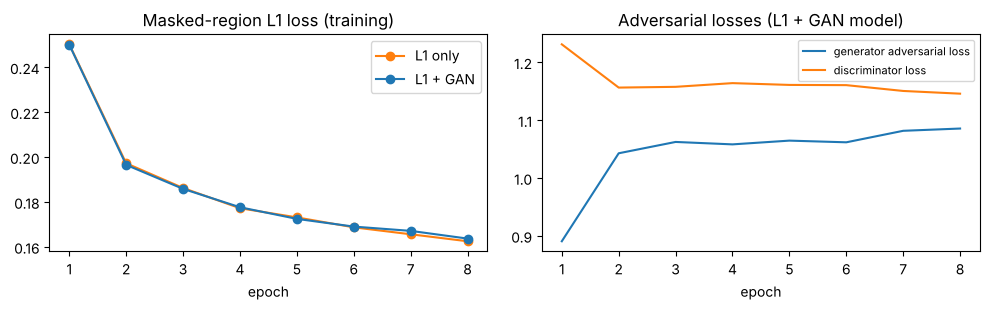

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for name, c in (("L1 only", "tab:orange"), ("L1 + GAN", "tab:blue")):
    h = np.array(hist[name]); ax[0].plot(range(1, EPOCHS + 1), h[:, 0], "o-", c=c, label=name)
ax[0].set(title="Masked-region L1 loss (training)", xlabel="epoch"); ax[0].legend()
h = np.array(hist["L1 + GAN"]); ax[1].plot(range(1, EPOCHS + 1), h[:, 1], label="generator adversarial loss"); ax[1].plot(range(1, EPOCHS + 1), h[:, 2], label="discriminator loss")
ax[1].set(title="Adversarial losses (L1 + GAN model)", xlabel="epoch"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Evaluation on unseen images

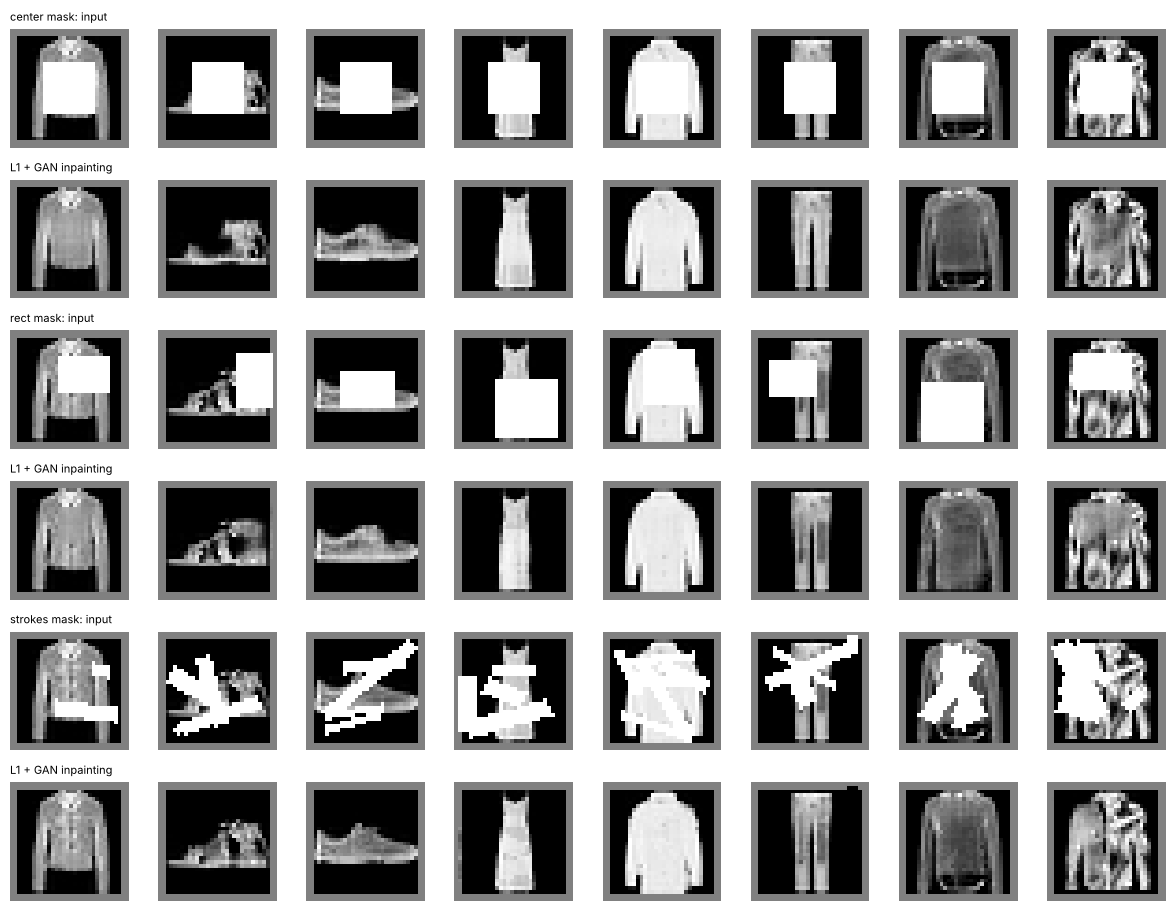

In [6]:
def inpaint(g, x, m):
    fake = g(tf.concat([x * (1 - m), m], -1), training=False).numpy()
    return fake * m + x * (1 - m)
kinds = ["center", "rect", "strokes"]
rows = []
fig, axes = plt.subplots(6, 8, figsize=(12, 9.2))
for r, kind in enumerate(kinds):
    ms = np.stack([make_mask(kind) for _ in range(8)]); xs = x_test[10:18]
    outs = {k: inpaint(g, xs, ms) for k, g in models.items()}
    for c in range(8):
        axes[2 * r, c].imshow(xs[c, ..., 0] * (1 - ms[c, ..., 0]) + ms[c, ..., 0], cmap="gray", vmin=-1, vmax=1)
        axes[2 * r + 1, c].imshow(outs["L1 + GAN"][c, ..., 0], cmap="gray", vmin=-1, vmax=1)
    axes[2 * r, 0].set_title(f"{kind} mask: input", fontsize=8, loc="left"); axes[2 * r + 1, 0].set_title("L1 + GAN inpainting", fontsize=8, loc="left")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

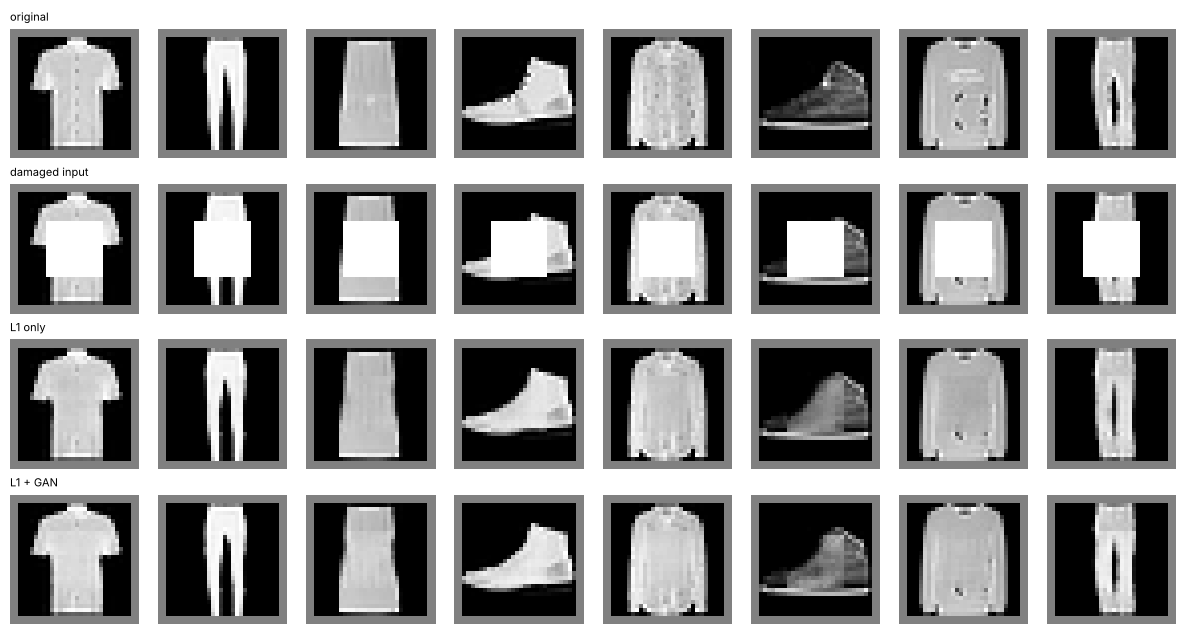

In [7]:
ms = np.stack([make_mask("center") for _ in range(8)]); xs = x_test[40:48]
outs = {k: inpaint(g, xs, ms) for k, g in models.items()}
fig, axes = plt.subplots(4, 8, figsize=(12, 6.4))
labels = ["original", "damaged input", "L1 only", "L1 + GAN"]
for c in range(8):
    for r, im in enumerate([xs[c], xs[c] * (1 - ms[c]) + ms[c], outs["L1 only"][c], outs["L1 + GAN"][c]]):
        axes[r, c].imshow(im[..., 0], cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(labels[r], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

mask     model       PSNR (dB)     SSIM   hole L1


center   L1 only         24.41   0.8185    0.0995


center   L1 + GAN        23.82   0.8087    0.1062


rect     L1 only         26.25   0.8915    0.0838


rect     L1 + GAN        25.86   0.8865    0.0886


strokes  L1 only         26.03   0.8849    0.0762


strokes  L1 + GAN        25.66   0.8798    0.0788



Baseline (hole filled with black): {'center': 12.38, 'rect': 14.76, 'strokes': 14.08} dB PSNR


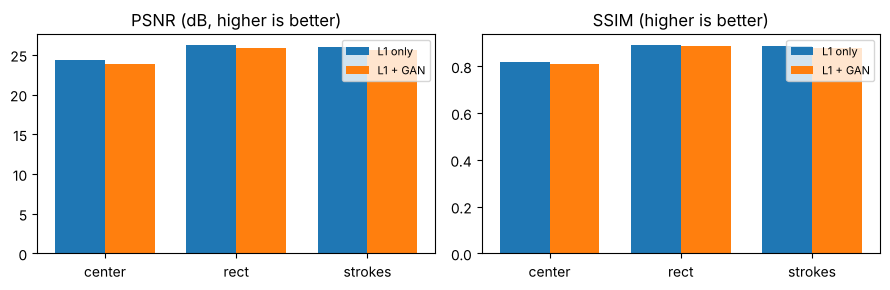

In [8]:
def evaluate(g, kind):
    ms = np.stack([make_mask(kind) for _ in range(len(x_test))])
    out = inpaint(g, x_test, ms)
    a, b = (x_test + 1) / 2, (out + 1) / 2
    psnr = np.minimum(tf.image.psnr(a, b, 1.0).numpy(), 50.0).mean();   # PSNR capped at 50 dB (perfect fills give infinity)
    ssim = tf.image.ssim(a, b, 1.0).numpy().mean()
    l1 = (np.abs(a - b) * ms).sum() / ms.sum()
    return psnr, ssim, l1
print(f"{'mask':8s} {'model':10s} {'PSNR (dB)':>10s} {'SSIM':>8s} {'hole L1':>9s}")
res = {}
for kind in kinds:
    for name, g in models.items():
        res[(kind, name)] = evaluate(g, kind)
        print(f"{kind:8s} {name:10s} {res[(kind, name)][0]:10.2f} {res[(kind, name)][1]:8.4f} {res[(kind, name)][2]:9.4f}")
baseline = {kind: evaluate(type("Z", (), {"__call__": lambda self, x, training=False: tf.zeros_like(x[..., :1]) - 1})(), kind) for kind in kinds}
print("\nBaseline (hole filled with black):", {k: round(float(v[0]), 2) for k, v in baseline.items()}, "dB PSNR")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
w = 0.38
for i, name in enumerate(models):
    ax[0].bar(np.arange(3) + i * w, [res[(k, name)][0] for k in kinds], w, label=name); ax[1].bar(np.arange(3) + i * w, [res[(k, name)][1] for k in kinds], w, label=name)
for a, t in zip(ax, ("PSNR (dB, higher is better)", "SSIM (higher is better)")):
    a.set_xticks(np.arange(3) + w / 2); a.set_xticklabels(kinds); a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); plt.show()